### Objective:
- Build a machine learning model to predict flight ticket prices based on airline, journey details, source, destination, duration, and other flight-related features.

### Task 1 : DATA ANALYSIS REPORT

1.DATA LOADING

In [107]:
import pandas as pd
import numpy as np

In [108]:
df =pd.read_excel(r"Flight_Fare.xlsx")

In [109]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [110]:
df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [111]:
df.shape

(10683, 11)

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


2.DATA CLEANING HANDLING MISSING VALUES:

In [113]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [114]:
df.dropna(inplace=True)

DATA PREPROCESSING

In [115]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [116]:
df.shape # one row removed

(10682, 11)

In [117]:
df.duplicated().sum()

np.int64(220)

In [118]:
df.drop_duplicates(inplace=True)

In [119]:
df.shape

(10462, 11)

In [120]:
df.duplicated().sum()

np.int64(0)

In [121]:
df.dtypes

Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

In [122]:
df.nunique() #checking unique values

Airline              12
Date_of_Journey      44
Source                5
Destination           6
Route               128
Dep_Time            222
Arrival_Time       1343
Duration            368
Total_Stops           5
Additional_Info      10
Price              1870
dtype: int64

In [123]:
df["Airline"].unique()

array(['IndiGo', 'Air India', 'Jet Airways', 'SpiceJet',
       'Multiple carriers', 'GoAir', 'Vistara', 'Air Asia',
       'Vistara Premium economy', 'Jet Airways Business',
       'Multiple carriers Premium economy', 'Trujet'], dtype=object)

In [124]:
df["Source"].unique()

array(['Banglore', 'Kolkata', 'Delhi', 'Chennai', 'Mumbai'], dtype=object)

In [125]:
df["Destination"].unique()

array(['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad'],
      dtype=object)

In [126]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


EXPLORATORY DATA ANALYSIS

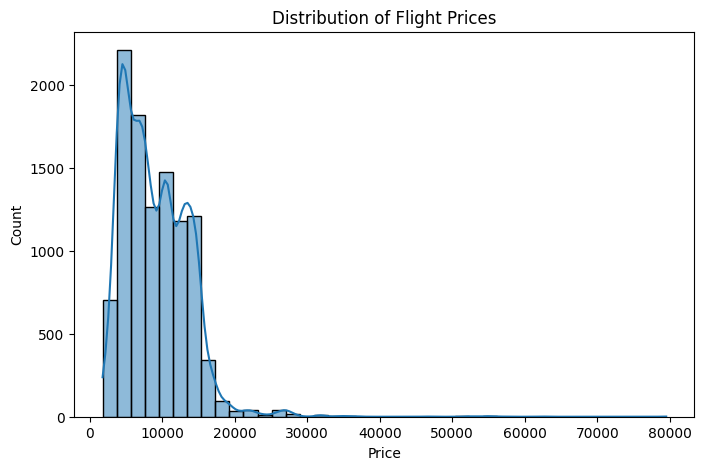

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(df["Price"], bins=40, kde=True)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Count")

plt.show()

## observation
- Most flight prices are between 3000 and 10,000.
- the distribution is right-skewed,indicating a few flights have very high prices.

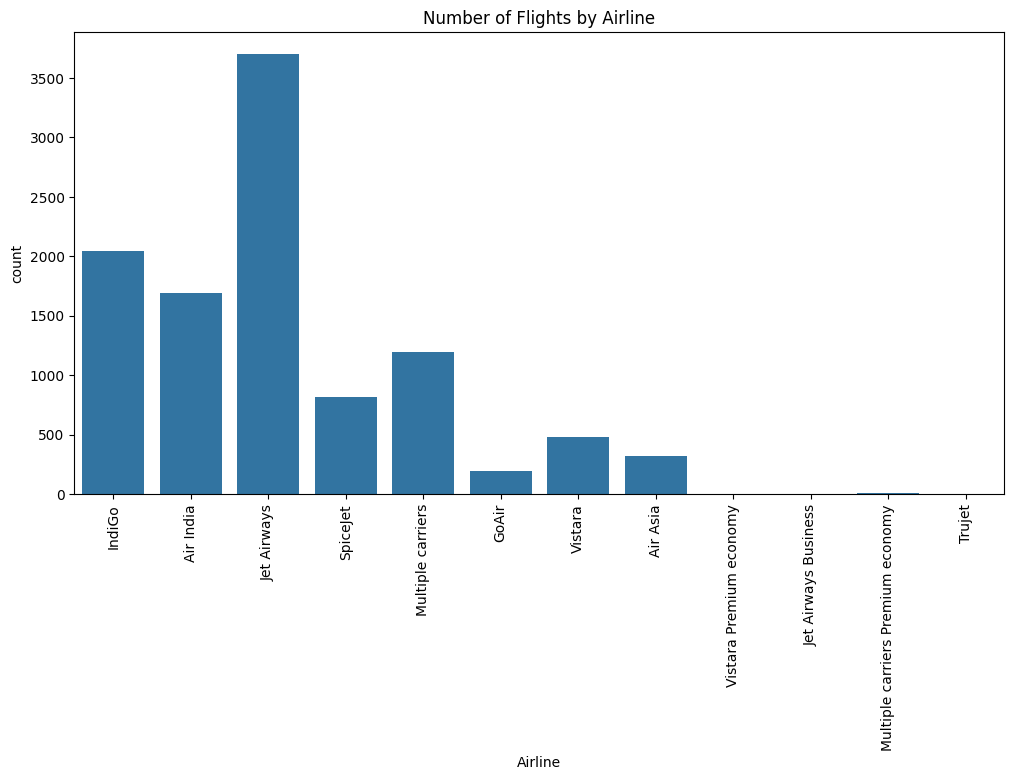

In [128]:
#Airline-wise Flight Count
plt.figure(figsize=(12,6))
sns.countplot(x="Airline",data=df)
plt.xticks(rotation=90)
plt.title("Number of Flights by Airline")

plt.show()

## Observation
- Indigo, Jetways, Air India, and Multiple Carriers operates highest number of flights.
- GoAir, Vistara, Air Asia have relatively fewer flights.


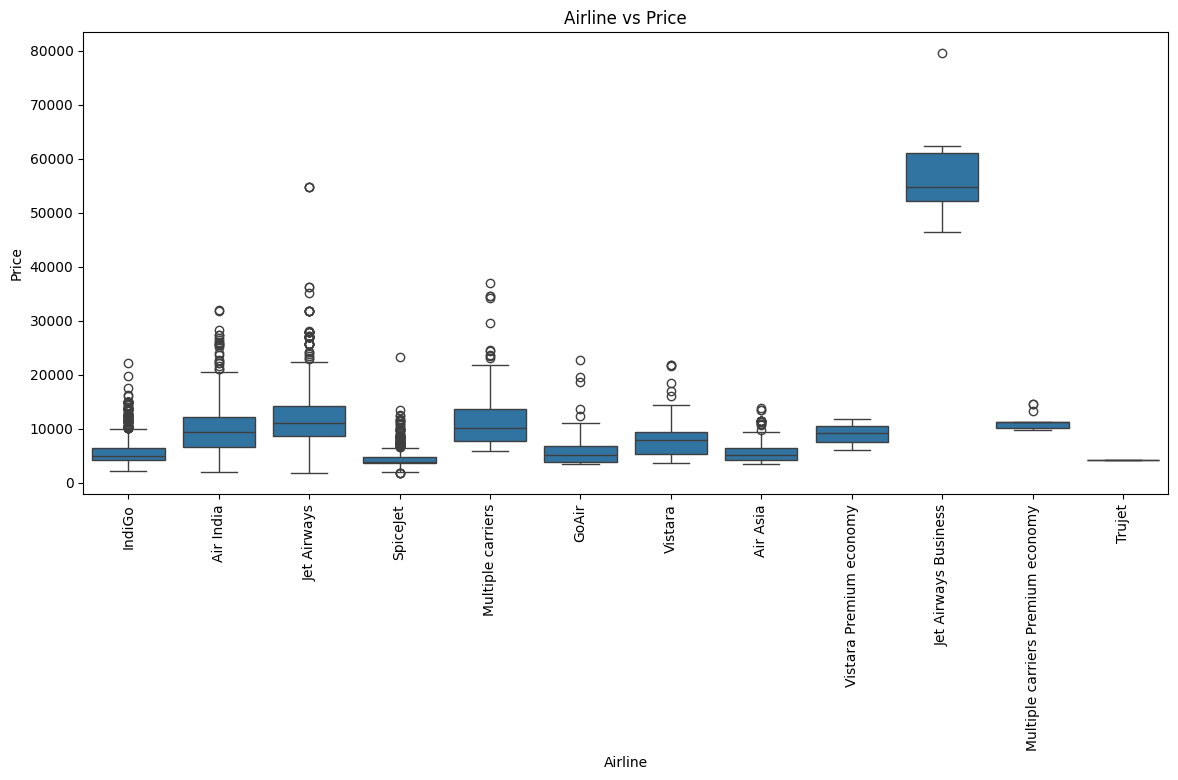

In [129]:
#AIRLINE VS PRICE
plt.figure(figsize=(14,6))
sns.boxplot(x="Airline", y="Price", data=df)
plt.xticks(rotation=90)
plt.title("Airline vs Price")

plt.show()

## Observation
- Jet Airways generally has higher ticket prices.
- Air India and Multiple carrier have median mrices.
- Indigo and SpiceJet have lower median prices.
- Some airlines have outliers with very expensive tickets.

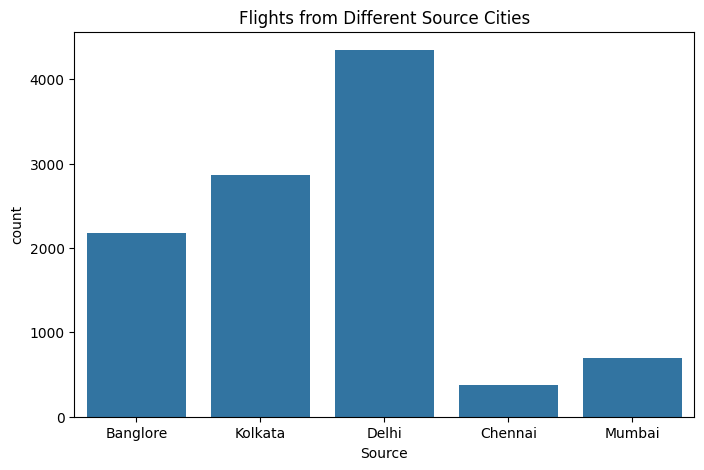

In [132]:
#Source-wise Flight Count
plt.figure(figsize=(8,5))
sns.countplot(x="Source", data=df)
plt.title("Flights from Different Source Cities")

plt.show()

## Observation
- Delhi and Kolkata has the highest number of flights.
- Chennai has the fewest flights.

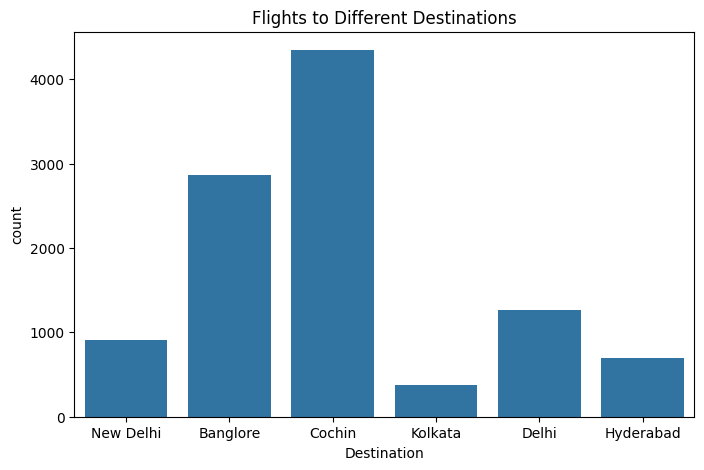

In [133]:
#Destination-wise Flight Count
plt.figure(figsize=(8,5))
sns.countplot(x="Destination" ,data=df)
plt.title("Flights to Different Destinations")

plt.show()

## Observation
- Cochin and Banglore has highest number of flights.
- Hyderabad and Kolkata recieves fewer flights.

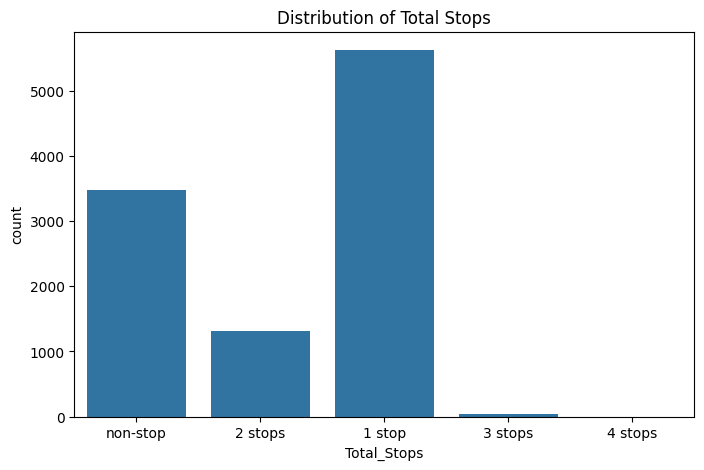

In [134]:
#Total Stops Distribution
plt.figure(figsize=(8,5))
sns.countplot(x="Total_Stops" , data=df)
plt.title("Distribution of Total Stops")

plt.show()

## Observation
- Most flights have 1 stop.
- Non-stop flights are the second most common.
- Flights with 3 or 4 stops are rare.

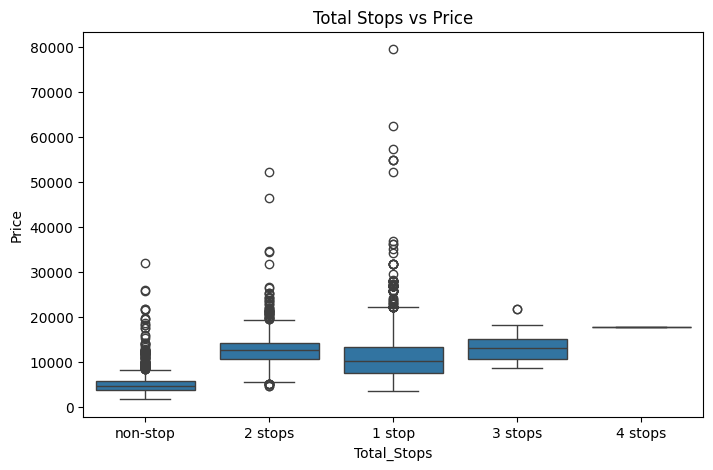

In [135]:
#Total Stops vs Price
plt.figure(figsize=(8,5))
sns.boxplot(x="Total_Stops",y="Price", data=df)
plt.title("Total Stops vs Price")

plt.show()

## Observation
- Flights with more stops generally have higher ticket prices.
- Non-stop flights have awider range of prices.

FEATURE ENGINEERING

In [136]:
df.head(1)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897


In [137]:
df["Journey_Day"]= pd.to_datetime(df["Date_of_Journey"]).dt.day
df["Journey_Month"]=pd.to_datetime(df["Date_of_Journey"]).dt.month

C:\Users\govar\AppData\Local\Temp\ipykernel_54624\4236478391.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Journey_Day"]= pd.to_datetime(df["Date_of_Journey"]).dt.day
C:\Users\govar\AppData\Local\Temp\ipykernel_54624\4236478391.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Journey_Month"]=pd.to_datetime(df["Date_of_Journey"]).dt.month


In [138]:
df.head(1)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3


In [139]:
df.drop("Date_of_Journey", axis=1 , inplace= True)

In [140]:
df.head(1)

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3


In [141]:
#Dep_Time
df["Dep_hour"] = pd.to_datetime(df["Dep_Time"]).dt.hour
df["Dep_Min"] = pd.to_datetime(df["Dep_Time"]).dt.minute

C:\Users\govar\AppData\Local\Temp\ipykernel_54624\1079412172.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dep_hour"] = pd.to_datetime(df["Dep_Time"]).dt.hour
C:\Users\govar\AppData\Local\Temp\ipykernel_54624\1079412172.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dep_Min"] = pd.to_datetime(df["Dep_Time"]).dt.minute


In [142]:
df.head(1)

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_Min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20


In [143]:
df.drop("Dep_Time", axis=1, inplace=True)

In [144]:
df.head(1)

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_Min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20


In [145]:
#Arrival_Time
df["Arrival_Hour"]=pd.to_datetime(df["Arrival_Time"]).dt.hour
df["Arrival_Min"]=pd.to_datetime(df["Arrival_Time"]).dt.minute

C:\Users\govar\AppData\Local\Temp\ipykernel_54624\631107950.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Arrival_Hour"]=pd.to_datetime(df["Arrival_Time"]).dt.hour
C:\Users\govar\AppData\Local\Temp\ipykernel_54624\631107950.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Arrival_Min"]=pd.to_datetime(df["Arrival_Time"]).dt.minute


In [146]:
df.head(1)

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_Min,Arrival_Hour,Arrival_Min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20,1,10


In [147]:
df.drop("Arrival_Time" , axis=1 , inplace=True)

In [148]:
df.head(1)

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_Min,Arrival_Hour,Arrival_Min
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,22,20,1,10


In [149]:
df["Duration"].head()

0    2h 50m
1    7h 25m
2       19h
3    5h 25m
4    4h 45m
Name: Duration, dtype: object

In [150]:
df["Duration_hours"] = df["Duration"].str.extract('(\d+)h')

In [151]:
df[["Duration","Duration_hours"]].head(10)

,Duration,Duration_hours
0,2h 50m,2
1,7h 25m,7
2,19h,19
3,5h 25m,5
4,4h 45m,4
5,2h 25m,2
6,15h 30m,15
7,21h 5m,21
8,25h 30m,25
9,7h 50m,7


In [152]:
df["Duration_minutes"] = df["Duration"].str.extract('(\d+)m')

In [153]:
df[["Duration","Duration_hours","Duration_minutes"]].head(10)

,Duration,Duration_hours,Duration_minutes
0,2h 50m,2,50
1,7h 25m,7,25
2,19h,19,NaN
3,5h 25m,5,25
4,4h 45m,4,45
5,2h 25m,2,25
6,15h 30m,15,30
7,21h 5m,21,5
8,25h 30m,25,30
9,7h 50m,7,50


In [154]:
df["Duration_hours"]=df["Duration_hours"].fillna(0).astype(int)
df["Duration_minutes"]=df["Duration_minutes"].fillna(0).astype(int)

In [155]:
df[["Duration" , "Duration_hours" , "Duration_minutes"]].head(10)

,Duration,Duration_hours,Duration_minutes
0,2h 50m,2,50
1,7h 25m,7,25
2,19h,19,0
3,5h 25m,5,25
4,4h 45m,4,45
5,2h 25m,2,25
6,15h 30m,15,30
7,21h 5m,21,5
8,25h 30m,25,30
9,7h 50m,7,50


In [156]:
#converting into decimal to understand by model
df["Duration"]=df["Duration_hours"] + (df["Duration_minutes"] / 60)

In [157]:
df[["Duration_hours", "Duration_minutes", "Duration" ]].head(10)
#Now the Duration column contains numeric values that the model can use.

,Duration_hours,Duration_minutes,Duration
0,2,50,2.833333
1,7,25,7.416667
2,19,0,19.000000
3,5,25,5.416667
4,4,45,4.750000
5,2,25,2.416667
6,15,30,15.500000
7,21,5,21.083333
8,25,30,25.500000
9,7,50,7.833333


In [158]:
df.drop(["Duration_hours" , "Duration_minutes"], axis=1 , inplace=True)

In [159]:
df.head()

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Dep_hour,Dep_Min,Arrival_Hour,Arrival_Min
0,IndiGo,Banglore,New Delhi,BLR → DEL,2.833333,non-stop,No info,3897,24,3,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7.416667,2 stops,No info,7662,1,5,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19.000000,2 stops,No info,13882,9,6,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5.416667,1 stop,No info,6218,12,5,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4.750000,1 stop,No info,13302,1,3,16,50,21,35


In [160]:
df["Total_Stops"].unique()

array(['non-stop', '2 stops', '1 stop', '3 stops', '4 stops'],
      dtype=object)

In [161]:
df["Total_Stops"] = df["Total_Stops"].map({
    "non-stop" : 0,
    "1 stop" : 1,
    "2 stops" : 2,
    "3 stops" : 3,
    "4 stops" : 4
})
                                          

In [162]:
df["Total_Stops"].head()

0    0
1    2
2    2
3    1
4    1
Name: Total_Stops, dtype: int64

In [163]:
df.select_dtypes(include="object").columns

Index(['Airline', 'Source', 'Destination', 'Route', 'Additional_Info'], dtype='object')

In [164]:
df["Additional_Info"].value_counts()

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [165]:
df["Route"].nunique()

128

In [166]:
df.drop("Additional_Info", axis=1, inplace=True)
#The Additional_Info column was analyzed before feature selection.
#Most of the records (around 77%) contained the value "No info", indicating very low variability. 
#Since the feature provided limited additional information and could introduce unnecessary categorical variables,
#it was removed from the dataset.

In [167]:
### Route Analysis
#The Route column contains 128 unique flight routes. Since it is a high-cardinality feature 
#and is closely related to the Source and Destination columns,it may introduce redundancy during model training.

In [168]:
df.drop("Route", axis=1 ,inplace = True)

In [169]:
df.select_dtypes(include="object").columns

Index(['Airline', 'Source', 'Destination'], dtype='object')

 Data Preprocessing Summary
- The dataset was cleaned by removing missing values and duplicate records.
- Date and time features were transformed into numerical features.
- Flight duration was converted into decimal hours. The `Total_Stops` feature was encoded into numerical values.
- The `Additional_Info` column was removed due to low variance, and the `Route` column was removed because of its high cardinality and redundancy with Source and Destination.
- Finally, One-Hot Encoding was applied to categorical features to prepare the data for machine learning models.

ONE HOT ENCODING

In [170]:
df=pd.get_dummies(df,columns=["Airline","Source","Destination"],drop_first=True,dtype=int)

In [171]:
df.head()

,Duration,Total_Stops,Price,Journey_Day,Journey_Month,Dep_hour,Dep_Min,Arrival_Hour,Arrival_Min,Airline_Air India,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,2.833333,0,3897,24,3,22,20,1,10,0,...,0,0,0,0,0,0,0,0,0,1
1,7.416667,2,7662,1,5,5,50,13,15,1,...,0,0,0,1,0,0,0,0,0,0
2,19.000000,2,13882,9,6,9,25,4,25,0,...,0,0,1,0,0,1,0,0,0,0
3,5.416667,1,6218,12,5,18,5,23,30,0,...,0,0,0,1,0,0,0,0,0,0
4,4.750000,1,13302,1,3,16,50,21,35,0,...,0,0,0,0,0,0,0,0,0,1


In [172]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10462 entries, 0 to 10682
Data columns (total 29 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Duration                                   10462 non-null  float64
 1   Total_Stops                                10462 non-null  int64  
 2   Price                                      10462 non-null  int64  
 3   Journey_Day                                10462 non-null  int32  
 4   Journey_Month                              10462 non-null  int32  
 5   Dep_hour                                   10462 non-null  int32  
 6   Dep_Min                                    10462 non-null  int32  
 7   Arrival_Hour                               10462 non-null  int32  
 8   Arrival_Min                                10462 non-null  int32  
 9   Airline_Air India                          10462 non-null  int64  
 10  Airline_GoAir              

CORRELATION HEATMAP

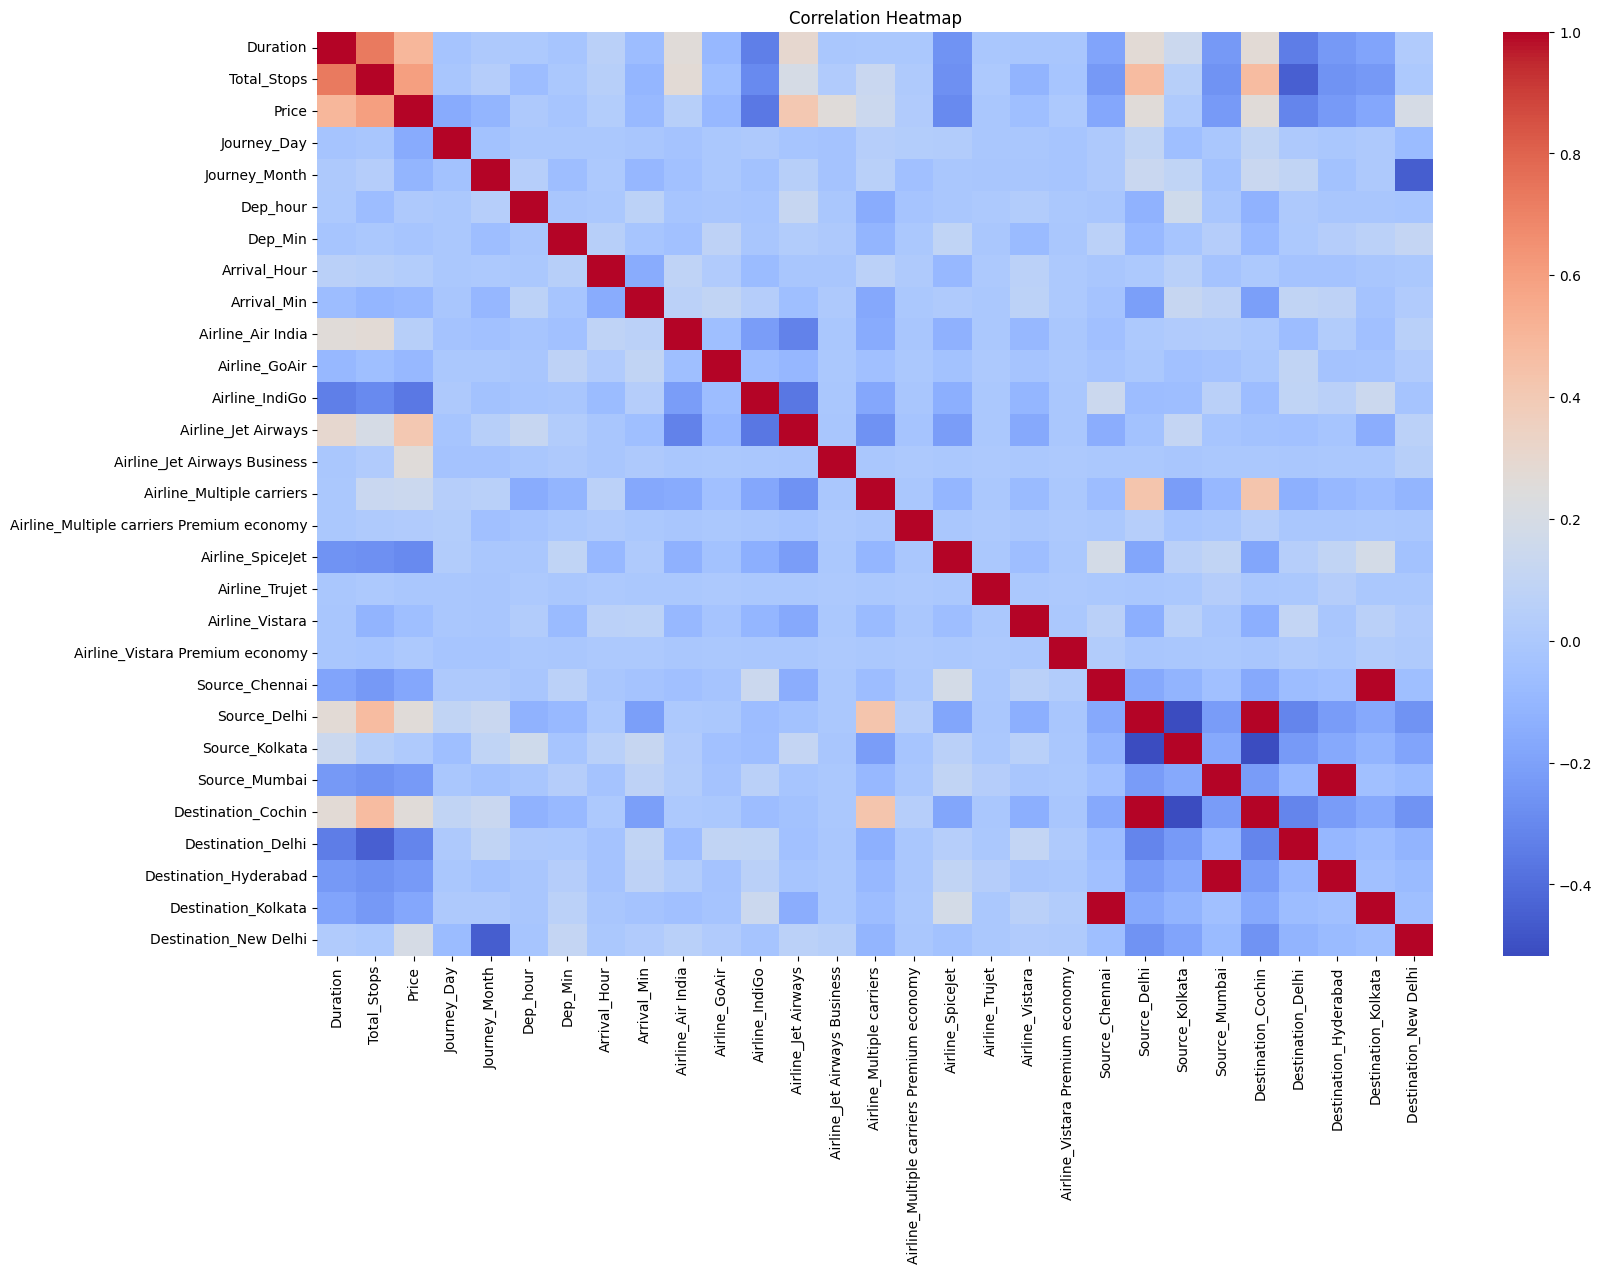

In [173]:
plt.figure(figsize=(18,12))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")

plt.show()

- Red (or darker warm colors) = Positive correlation.
- Blue (or cooler colors) = Negative correlation.
- Light colors = Weak or no correlation.

### Correlation Analysis

A correlation heatmap was generated to understand the relationship among the numerical features.

• Duration shows a positive correlation with Price, indicating that longer flights generally have higher ticket prices.

• Total_Stops is also positively correlated with Price and Duration, suggesting that flights with more stops usually have longer travel times and may cost more.

• Most airline, source, and destination features show weak to moderate correlations with Price.

• No severe multicollinearity was observed among the selected features, making the dataset suitable for machine learning.

In [174]:
#X = Input features (everything except Price)
#y = Target variable (Price)
x = df.drop("Price" , axis=1)
y = df["Price"]

In [175]:
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (10462, 28)
y shape: (10462,)


### TASK 2 : FINDING PREDICTIVE MODEL TO PREDICT FUTURE FLIGHT PRICES

Train-Test Split
- The dataset was divided into training and testing sets using an 80:20 ratio. The training set is used to train the machine learning model, while the testing set is used to evaluate its performance on unseen data. A random state of 42 was used to ensure reproducibility.

In [176]:
from sklearn.model_selection import train_test_split

In [177]:
x_train,x_test,y_train,y_test = train_test_split(x , y , test_size = 0.2  , random_state = 42 )

In [178]:
print("x_train:" , x_train.shape)
print("x_test:" , x_test.shape)
print("y_train:" , y_train.shape)
print("y_test:" , y_test.shape)

x_train: (8369, 28)
x_test: (2093, 28)
y_train: (8369,)
y_test: (2093,)


MODEL BUILDING

In [179]:
#LINEAR REGRESSION
from sklearn.linear_model import LinearRegression

lr = LinearRegression() #created empty linearregression model

In [180]:
lr.fit(x_train , y_train) 

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [181]:
y_pred_lr = lr.predict(x_test)

In [182]:
comparison = pd.DataFrame({ "Actual Price" : y_test,
                            "Predicted Price" : y_pred_lr})

In [183]:
comparison.head(10)

,Actual Price,Predicted Price
2150,17996,14546.186619
3784,3873,4536.303684
714,4462,4779.974836
7558,2228,7085.112503
7413,4991,2525.640410
6678,7670,10427.703736
3763,14086,12290.040451
10303,6386,6995.779511
10595,6628,8010.928008
10186,6934,5591.003191


###"The table compares the actual flight ticket prices from the test dataset with the prices predicted by the Linear Regression model. It helps us visually inspect how close the model's predictions are to the actual values before evaluating the model using statistical metrics."

In [184]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
import numpy as np

In [185]:
print("R2 Score:" , r2_score(y_test , y_pred_lr))
print("MAE:" , mean_absolute_error(y_test , y_pred_lr))
print("MSE:" , mean_squared_error(y_test , y_pred_lr))
print("RMSE:" ,np.sqrt(mean_squared_error(y_test , y_pred_lr)))

R2 Score: 0.5838081325633984
MAE: 1998.6393059377087
MSE: 8677715.462290764
RMSE: 2945.7962357044935


In [186]:
##"Each evaluation metric measures a different aspect of model performance.
#R² tells us how well the model explains the variation in the target variable. 
#MAE gives the average prediction error. 
#MSE penalizes larger errors more heavily.
#RMSE expresses the error in the same unit as the target variable.
#Using all four metrics provides a more complete evaluation of the model."

DECISION TREE REGRESSION

In [187]:
from sklearn.tree import DecisionTreeRegressor

In [188]:
dt = DecisionTreeRegressor(random_state = 42)

In [189]:
dt.fit(x_train , y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [190]:
y_pred_dt = dt.predict(x_test)

In [191]:
print("R2 Score:" , r2_score(y_test , y_pred_dt))
print("MAE:" , mean_absolute_error(y_test , y_pred_dt))
print("MSE:" , mean_squared_error(y_test , y_pred_dt))
print("RMSE:" , np.sqrt(mean_squared_error(y_test , y_pred_dt)))

R2 Score: 0.7186121852246886
MAE: 1381.6644768275203
MSE: 5867013.7074408075
RMSE: 2422.1919220905693


In [192]:
#A Decision Tree Regressor was trained to predict flight ticket prices. Unlike Linear Regression,
#the Decision Tree model learns decision rules by splitting the data into smaller groups based on feature values.
#This enables it to capture complex and non-linear relationships between the features and the target variable.

RANDOM FOREST REGRESSION

In [193]:
from sklearn.ensemble import RandomForestRegressor

In [194]:
rf = RandomForestRegressor(n_estimators=100 , random_state=42)

In [195]:
rf.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [196]:
y_pred_rf = rf.predict(x_test)

In [197]:
print("R2 Score:" , r2_score(y_test,y_pred_rf))
print("MAE:" , mean_absolute_error(y_test,y_pred_rf))
print("MSE:" , mean_squared_error(y_test,y_pred_rf))
print("RMSE:" ,np.sqrt(mean_squared_error(y_test,y_pred_rf)))

R2 Score: 0.8143723284420574
MAE: 1172.1906601559242
MSE: 3870388.255370623
RMSE: 1967.3302354639454


In [198]:
###Random Forest Regression
#Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve prediction accuracy and reduce overfitting.
#Each tree is trained on a random subset of the data, and the final prediction is obtained by averaging the predictions from all trees.
#The Random Forest model was trained using 100 decision trees (`n_estimators=100`) and evaluated using R² Score, MAE, MSE, and RMSE.

### Final Observation
- Random Forest outperformed both Linear Regression and Decision Tree across all evaluation metrics.
- It achieved the highest R² Score (81.4%) and the lowest prediction errors (MAE, MSE, and RMSE).
- Therefore, Random Forest was selected as the best model for predicting flight ticket prices.

In [199]:
from sklearn.ensemble import GradientBoostingRegressor

In [200]:
gb = GradientBoostingRegressor(n_estimators = 100 , random_state = 42)

In [201]:
gb.fit(x_train , y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [202]:
y_pred_gb = gb.predict(x_test)

In [203]:
print("R2 Score:", r2_score(y_test , y_pred_gb))
print("MAE:", mean_absolute_error(y_test , y_pred_gb))
print("MSE:", mean_squared_error(y_test , y_pred_gb))
print("RMSE:",np.sqrt(mean_squared_error(y_test, y_pred_gb)))

R2 Score: 0.7533868895568949
MAE: 1536.4498162660868
MSE: 5141951.511154275
RMSE: 2267.587156242131


In [204]:
#Gradient Boosting is an ensemble learning technique that builds multiple decision trees sequentially.
#Each new tree attempts to reduce the prediction errors made by the previous trees.
#This approach often improves prediction accuracy for regression problems.
#The model was evaluated using R² Score, MAE, MSE, and RMSE to compare its performance with other regression models.

## Model Comparison
Four regression models were trained and evaluated using R² Score, MAE, MSE, and RMSE.
    
| Model | R² Score | MAE | RMSE |
|-------|----------|---------|---------|
| Linear Regression | 0.584 | 1998.64 | 2945.80 |
| Decision Tree | 0.719 | 1381.66 | 2422.19 |
| Gradient Boosting | 0.753 | 1536.45 | 2267.59 |
| Random Forest | 0.814 | 1172.19 | 1967.33 |

### Observation
Random Forest achieved the highest R² Score and the lowest prediction errors among all the models.
Therefore, it was selected as the final model for predicting flight ticket prices.

Extract Feature Importance

In [205]:
importance = rf.feature_importances_

In [206]:
importance

array([4.57607370e-01, 2.91259729e-02, 1.31606957e-01, 5.84933240e-02,
       2.68994789e-02, 2.56756623e-02, 3.36199808e-02, 2.19214841e-02,
       4.90640468e-03, 1.95997690e-03, 6.69028055e-03, 5.96763809e-02,
       7.77305523e-02, 1.82989323e-02, 7.49755606e-04, 2.39672990e-03,
       1.51654647e-05, 2.92266990e-03, 3.96132354e-05, 5.55021275e-04,
       2.68763800e-03, 4.03499239e-03, 3.96798133e-03, 3.09331782e-03,
       4.26791163e-04, 3.52453595e-03, 5.81564784e-04, 2.07914660e-02])

In [207]:
feature_importance = pd.DataFrame({"Feature":x.columns , "Importance":importance})

In [208]:
feature_importance = feature_importance.sort_values(by = "Importance", ascending = False)

In [209]:
feature_importance.head(10)

,Feature,Importance
0,Duration,0.457607
2,Journey_Day,0.131607
12,Airline_Jet Airways Business,0.077731
11,Airline_Jet Airways,0.059676
3,Journey_Month,0.058493
6,Arrival_Hour,0.033620
1,Total_Stops,0.029126
4,Dep_hour,0.026899
5,Dep_Min,0.025676
7,Arrival_Min,0.021921


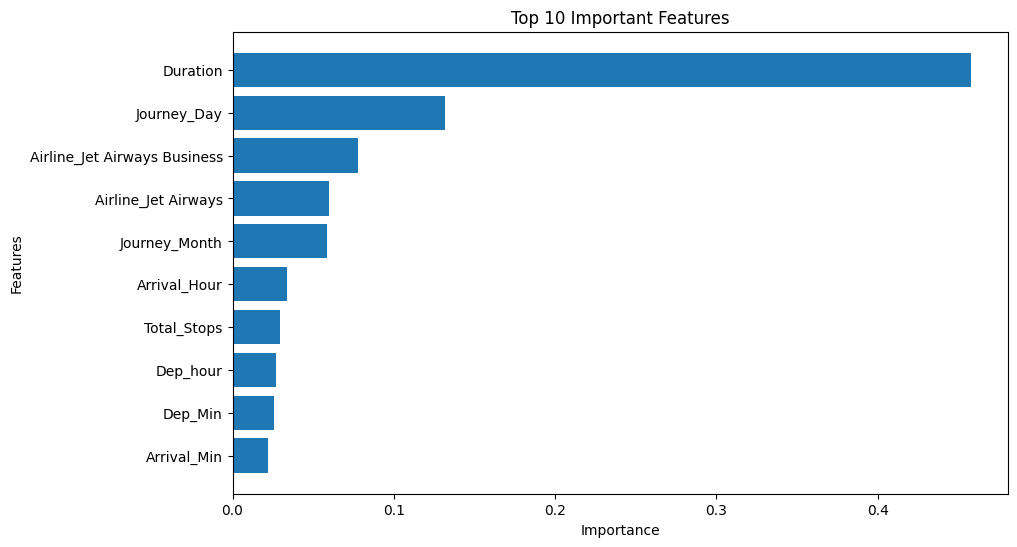

In [210]:
top10 = feature_importance.head(10)

plt.figure(figsize=(10,6))
plt.barh(top10["Feature"] , top10["Importance"])
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")
plt.gca().invert_yaxis()
plt.show()


## Observation
- Duration is the most important feature.
- Journey Day also influences price.
- Airline plays a significant role.
- Duration contributes the most.

In [211]:
model_comparison = pd.DataFrame({
    "Model" : ["Linear Regression","Decision Tree","Random Forest","Gradient Boosting"],
    "R2 Score" : [0.5838, 0.7186, 0.8144, 0.7534],
    "MAE" : [1998.64, 1381.66, 1172.19, 1536.45],
    "RMSE" : [2945.80, 2422.19, 1967.33, 2267.59]
})

model_comparison

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.5838,1998.64,2945.80
1,Decision Tree,0.7186,1381.66,2422.19
2,Random Forest,0.8144,1172.19,1967.33
3,Gradient Boosting,0.7534,1536.45,2267.59


#Visualize Model Comparison : R2 SCORE

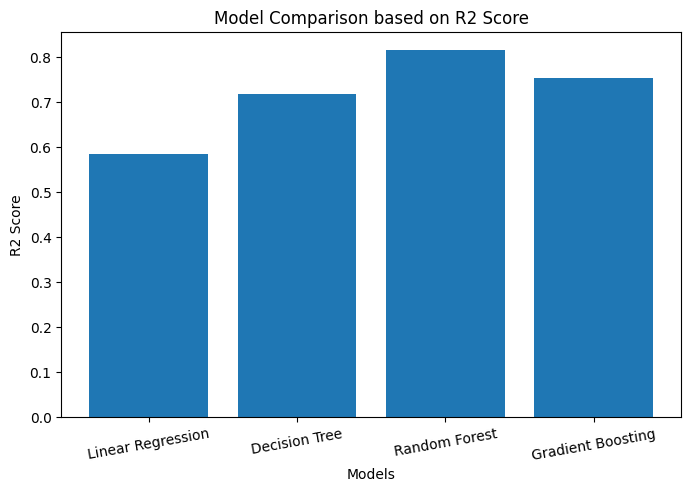

In [212]:
plt.figure(figsize=(8,5))
plt.bar(model_comparison["Model"] , model_comparison["R2 Score"])
plt.title("Model Comparison based on R2 Score")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=10)

plt.show()

# MODEL COMPARISON

 ## Observation

- Four regression models were trained and evaluated.
- Random Forest achieved the highest R² Score (0.8144).
- It also produced the lowest MAE and RMSE values.
- Therefore, Random Forest was selected as the final model for predicting flight ticket prices.

# Challenges Faced

During this project, the following challenges were encountered:

- Handling missing values in the dataset.
- Converting the Date_of_Journey column into separate day and month features.
- Extracting hour and minute values from Departure and Arrival time columns.
- Converting the Duration column from text format into numerical hours.
- Encoding categorical variables (Airline, Source, and Destination) using One-Hot Encoding.
- Selecting the best machine learning model by comparing multiple regression algorithms.

# Conclusion

In this project, a Flight Fare Prediction model was developed using machine learning techniques. The dataset was preprocessed by handling missing values, performing feature engineering, and encoding categorical variables. Four regression models were trained and evaluated using R² Score, MAE, MSE, and RMSE.

Among all the models, the Random Forest Regressor achieved the best performance with:
- R² Score = 0.8144
- MAE = 1172.19
- RMSE = 1967.33

Therefore, Random Forest was selected as the final model for predicting flight ticket prices.

# Future Scope

- Improve model performance using hyperparameter tuning.
- Compare the performance with advanced boosting algorithms such as XGBoost.